# Part A1 — Baseline Model and Hyperparameter Optimisation

This notebook reproduces the provided HDB-price baseline, performs the required Ray grid search, selects the architecture with the lowest best validation RMSE, and then retrains the selected model on the combined training and validation data.

**Data usage**
- **2017–2020:** training during hyperparameter selection
- **2021:** validation and model selection
- **2022:** final test set
- After model selection, **2017–2021** are combined for final retraining, and preprocessing is re-fit on this combined training data only.

**Search space**
- Hidden-layer width: `{16, 32, 64, 128, 256}`
- Shared embedding dimension: `{2, 4, 8, 12, 16}`

The provided baseline uses Adam, a maximum of 20 epochs, patience 4, and minimum validation-RMSE improvement of `1e-4` during model selection.

## 1. Environment and project setup

In [27]:
from pathlib import Path
import sys
import copy
import math

import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import DataLoader

BASELINE_NUM_THREADS = torch.get_num_threads()

import ray
from ray import tune

### Project paths and source imports

In [28]:
ROOT = Path.cwd()
SRC = ROOT / "src"

if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from config import Config
from data import prepare_data, make_dataset
from model import PriceModel

DATA_PATH = ROOT / "hdb_price_prediction.csv"
OUTPUT_DIR = ROOT / "outputs" / "A1"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)
print("Data exists:", DATA_PATH.exists())
print("PyTorch version:", torch.__version__)
print("Ray version:", ray.__version__)

Project root: d:\NTU\26sem1\SC4001\housing_baseline_data\hdb-price-prediction-assignment-main
Data exists: True
PyTorch version: 2.13.0+cpu
Ray version: 2.58.0


### Environment verification

Part A1 and Part A2 are intended to run from the same project root and the same project `.venv`.  
The cell below records the exact Python executable and package versions used at runtime. When preparing the final ZIP/README, run both notebooks with the same VS Code kernel and confirm that these values match.

In [ ]:
from importlib.metadata import version as package_version

python_executable = Path(sys.executable).resolve()
project_venv = (ROOT / ".venv").resolve()

print("Python executable:", python_executable)
print("Python version:", sys.version.split()[0])
print("Project .venv:", project_venv)
print("Using project .venv:", str(project_venv).lower() in str(python_executable).lower())

for package in ["torch", "ray", "pandas", "numpy", "matplotlib"]:
    try:
        print(f"{package}: {package_version(package)}")
    except Exception:
        print(f"{package}: not installed")

## 2. Baseline architecture and trainable parameters

The provided baseline contains four categorical embedding tables and six standardised continuous inputs.  
This section inspects the categorical cardinalities, the baseline dimensions, and the total number of trainable parameters used by the supplied baseline architecture.

In [3]:
baseline_config = Config()

data = prepare_data(DATA_PATH, baseline_config)

print("Categorical features:")
for name, cardinality, emb_dim in zip(
    baseline_config.categorical_features,
    data["cardinalities"],
    baseline_config.embedding_dims
):
    print(
        f"{name:20s} cardinality={cardinality:3d}, "
        f"embedding_dim={emb_dim}"
    )

print("\nContinuous features:")
for name in baseline_config.continuous_features:
    print(name)

print("\nBaseline hidden width:", baseline_config.hidden_width)

baseline_model = PriceModel(
    cardinalities=data["cardinalities"],
    target_mean=data["target_mean"],
    target_std=data["target_std"],
    config=baseline_config,
)

total_trainable_params = 0

print(f"{'Parameter':45s} {'Shape':20s} {'Count':>10s}")
print("-" * 80)

for name, parameter in baseline_model.named_parameters():
    if parameter.requires_grad:
        count = parameter.numel()
        total_trainable_params += count

        print(
            f"{name:45s} "
            f"{str(tuple(parameter.shape)):20s} "
            f"{count:10d}"
        )

print("-" * 80)
print(f"Total trainable parameters: {total_trainable_params:,}")

Categorical features:
month                cardinality= 13, embedding_dim=8
town                 cardinality= 27, embedding_dim=8
flat_model_type      cardinality= 44, embedding_dim=8
storey_range         cardinality= 18, embedding_dim=8

Continuous features:
dist_to_nearest_stn
dist_to_dhoby
degree_centrality
eigenvector_centrality
remaining_lease_years
floor_area_sqm

Baseline hidden width: 64
Parameter                                     Shape                     Count
--------------------------------------------------------------------------------
embeddings.0.weight                           (13, 8)                     104
embeddings.1.weight                           (27, 8)                     216
embeddings.2.weight                           (44, 8)                     352
embeddings.3.weight                           (18, 8)                     144
mlp.0.weight                                  (64, 38)                   2432
mlp.0.bias                                    (64,) 

## 3. Hyperparameter optimisation with Ray Tune

For each of the 25 configurations, the model is trained on 2017–2020 and evaluated on the 2021 validation set. Early stopping uses validation RMSE. The selected configuration is the one with the **lowest best validation RMSE**.

### Final regression evaluation function

In [4]:
@torch.no_grad()
def calculate_rmse(model, dataset, batch_size):
    model.eval()
    predictions = []
    targets = []
    for categorical, continuous, target in DataLoader(dataset, batch_size=batch_size):
        predictions.append(model.predict_price(categorical, continuous))
        targets.append(target)

    prediction = torch.cat(predictions)
    target = torch.cat(targets)
    return (prediction - target).square().mean().sqrt().item()

### 3.2 Train one configuration

This function keeps the supplied preprocessing, optimiser, learning rate, batch size, early-stopping rule, and seed unchanged while varying only hidden width and the shared embedding dimension.

In [5]:
def train_one_configuration(hidden_width,embedding_dim,verbose=False):
    # --------------------------------------------------------
    # Configuration
    # --------------------------------------------------------
    config = Config(
        hidden_width=int(hidden_width),
        embedding_dims=(
            int(embedding_dim),
            int(embedding_dim),
            int(embedding_dim),
            int(embedding_dim),
        ),
    )
    # Same seed as baseline
    torch.manual_seed(config.seed)
    torch.use_deterministic_algorithms(True, warn_only=True)
    # --------------------------------------------------------
    # Prepare data
    # --------------------------------------------------------
    data = prepare_data(DATA_PATH,config)

    # --------------------------------------------------------
    # Create model
    # --------------------------------------------------------
    model = PriceModel(
        cardinalities=data["cardinalities"],
        target_mean=data["target_mean"],
        target_std=data["target_std"],
        config=config,
    )
    train_loader = DataLoader(
        data["train"],
        batch_size=config.batch_size,
        shuffle=True,
    )
    loss_function = nn.MSELoss()
    optimiser = torch.optim.Adam(
        model.parameters(),
        lr=config.learning_rate,
    )
    # --------------------------------------------------------
    # Early stopping variables
    # --------------------------------------------------------
    best_validation_rmse = float("inf")
    best_weights = None
    best_epoch = 0
    epochs_without_improvement = 0
    train_rmse_history = []
    validation_rmse_history = []
    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------
    for epoch in range(
        1,
        config.max_epochs + 1
    ):
        model.train()
        squared_error = 0.0
        row_count = 0
        for categorical, continuous, target in train_loader:
            optimiser.zero_grad()
            # Standardised model prediction
            standard_prediction = model(categorical,continuous)
            # Standardise target exactly as baseline.py
            standard_target = (target - model.target_mean) / model.target_std
            loss = loss_function(standard_prediction,standard_target)
            loss.backward()
            optimiser.step()
            # Convert prediction back to SGD
            prediction = (standard_prediction.detach()* model.target_std + model.target_mean)
            squared_error += ((prediction - target).square().sum().item())
            row_count += len(target)
        # ----------------------------------------------------
        # RMSE
        # ----------------------------------------------------
        train_rmse = math.sqrt(squared_error / row_count)
        validation_rmse = calculate_rmse(
            model,
            data["validation"],
            config.batch_size,
        )
        train_rmse_history.append(train_rmse)
        validation_rmse_history.append(
            validation_rmse
        )
        if verbose:
            print(
                f"epoch {epoch:02d} | "
                f"train RMSE {train_rmse:,.2f} | "
                f"validation RMSE "
                f"{validation_rmse:,.2f}"
            )
        # ----------------------------------------------------
        # Early stopping
        # ----------------------------------------------------
        if (
            best_weights is None
            or validation_rmse < best_validation_rmse - config.early_stopping_threshold
        ):
            best_validation_rmse = (validation_rmse)

            best_weights = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if (epochs_without_improvement == config.early_stopping_patience):
                if verbose:
                    print(
                        f"Early stopping after "
                        f"epoch {epoch}"
                    )
                break
    # Restore best model
    model.load_state_dict(best_weights)
    return {
        "model": model,
        "config": config,
        "data": data,
        "best_epoch": best_epoch,
        "best_validation_rmse":
            best_validation_rmse,
        "train_rmse_history":
            train_rmse_history,
        "validation_rmse_history":
            validation_rmse_history,
    }

### 3.3 Baseline reproduction check

Before launching the grid search, the original configuration `(hidden width = 64, embedding dimension = 8)` is rerun. Matching the supplied baseline provides a sanity check that the training pipeline has not changed.

In [6]:
baseline_check = train_one_configuration(
    hidden_width=64,
    embedding_dim=8,
    verbose=True,
)
best_train_rmse = calculate_rmse(
    baseline_check["model"],
    baseline_check["data"]["train"],
    baseline_check["config"].batch_size
)
print()
print("Best epoch:", baseline_check["best_epoch"])
print(f"train RMSE: {best_train_rmse:,.0f}")
print("Best validation RMSE:", f'{baseline_check["best_validation_rmse"]:,.2f}')

epoch 01 | train RMSE 54,244.53 | validation RMSE 70,796.46
epoch 02 | train RMSE 37,121.95 | validation RMSE 68,430.55
epoch 03 | train RMSE 35,399.18 | validation RMSE 75,549.55
epoch 04 | train RMSE 34,594.67 | validation RMSE 63,283.25
epoch 05 | train RMSE 33,988.68 | validation RMSE 64,439.45
epoch 06 | train RMSE 33,488.52 | validation RMSE 65,684.55
epoch 07 | train RMSE 33,192.83 | validation RMSE 69,746.75
epoch 08 | train RMSE 32,918.99 | validation RMSE 66,473.35
Early stopping after epoch 8

Best epoch: 4
train RMSE: 33,970
Best validation RMSE: 63,283.25


### 3.4 Ray Tune trainable

In [7]:
def ray_trainable(ray_config):
    torch.set_num_threads(BASELINE_NUM_THREADS)

    result = train_one_configuration(
        hidden_width=ray_config["hidden_width"],
        embedding_dim=ray_config["embedding_dim"],
        verbose=False
    )

    tune.report({
        "best_validation_rmse": result["best_validation_rmse"],
        "best_epoch": result["best_epoch"]
    })

### 3.5 Define the 5 × 5 grid-search space

In [8]:
search_space = {
    "hidden_width": tune.grid_search([16, 32, 64, 128, 256]),
    "embedding_dim": tune.grid_search([2, 4, 8, 12, 16]),
}
print("Total configurations:", 5*5)

Total configurations: 25


In [ ]:
# Shut down a previous Ray session if needed
if ray.is_initialized():
    ray.shutdown()

ray.init(
    num_cpus=BASELINE_NUM_THREADS,
    runtime_env={"working_dir": str(SRC)},
    include_dashboard=False,
    ignore_reinit_error=True
)

trainable_with_resources = tune.with_resources(
    ray_trainable,
    resources={"cpu": BASELINE_NUM_THREADS}
)

tuner = tune.Tuner(
    trainable_with_resources,
    param_space=search_space,
    tune_config=tune.TuneConfig(
        metric="best_validation_rmse",
        mode="min",
        max_concurrent_trials=1
    )
)

ray_results = tuner.fit()

### 3.6 Grid-search results

In [10]:
grid_rows = []

for result in ray_results:

    grid_rows.append({
        "hidden_width":
            result.config["hidden_width"],
        "embedding_dim":
            result.config["embedding_dim"],
        "best_epoch":
            int(result.metrics["best_epoch"]),
        "best_validation_rmse":
            float(
                result.metrics[
                    "best_validation_rmse"
                ]
            ),
    })

grid_results_df = pd.DataFrame(grid_rows)

grid_results_df = (
    grid_results_df
    .sort_values(
        "best_validation_rmse"
    )
    .reset_index(drop=True)
)

grid_results_df

,hidden_width,embedding_dim,best_epoch,best_validation_rmse
0,256,2,10,59880.894531
1,128,12,13,59926.554688
2,256,4,3,61177.347656
3,128,4,4,61553.562500
4,16,12,7,62513.582031
5,32,4,4,62762.535156
6,256,16,5,63056.183594
7,32,12,5,63206.796875
8,64,16,5,63279.957031
9,64,8,4,63283.250000


### 3.7 Selected hyperparameters

In [11]:
best_row = grid_results_df.iloc[0]

best_hidden_width = int(best_row["hidden_width"])
best_embedding_dim = int(best_row["embedding_dim"])
best_epoch = int(best_row["best_epoch"])
best_validation_rmse = float(best_row["best_validation_rmse"])

print("Optimal hidden width:",best_hidden_width)
print("Optimal embedding dimension:",best_embedding_dim)
print("Best epoch:",best_epoch)
print("Best validation RMSE:",f"{best_validation_rmse:,.2f}")

Optimal hidden width: 256
Optimal embedding dimension: 2
Best epoch: 10
Best validation RMSE: 59,880.89


### 3.8 Grid-search heatmap

The heatmap visualises the best validation RMSE attained by each of the 25 configurations.

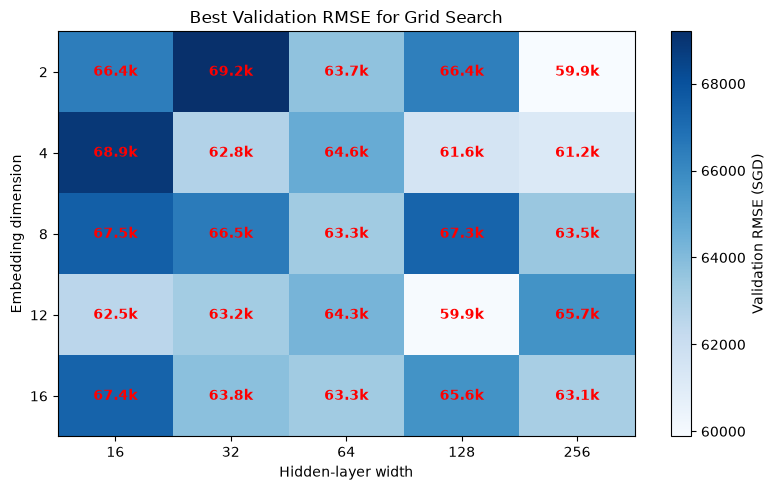

In [12]:
heatmap_data = grid_results_df.pivot(
    index="embedding_dim",
    columns="hidden_width",
    values="best_validation_rmse",
)

fig, ax = plt.subplots(figsize=(8, 5))

# Light blue -> dark blue
im = ax.imshow(
    heatmap_data.values,
    aspect="auto",
    cmap="Blues"
)

ax.set_xticks(range(len(heatmap_data.columns)))
ax.set_xticklabels(heatmap_data.columns)
ax.set_yticks(range(len(heatmap_data.index)))
ax.set_yticklabels(heatmap_data.index)
ax.set_xlabel("Hidden-layer width")
ax.set_ylabel("Embedding dimension")
ax.set_title("Best Validation RMSE for Grid Search")

cbar = plt.colorbar(im,ax=ax)

cbar.set_label(
    "Validation RMSE (SGD)"
)

# Add RMSE values in red
for i in range(len(heatmap_data.index)):
    for j in range(len(heatmap_data.columns)):

        value = heatmap_data.iloc[i, j]

        ax.text(
            j,
            i,
            f"{value/1000:.1f}k",
            ha="center",
            va="center",
            color="red",
            fontsize=10,
            fontweight="bold"
        )

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "grid_search_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 4. Selected A1 settings

The selected hidden width, embedding dimension, and best epoch are stored once and reused for the learning-curve analysis and final retraining.

In [14]:
HIDDEN_WIDTH = best_hidden_width
EMBEDDING_DIM = best_embedding_dim
NUM_EPOCHS = best_epoch

evaluation function

In [15]:
@torch.no_grad()
def evaluate_regression(model, dataset, batch_size):
    model.eval()
    predictions = []
    targets = []

    for categorical, continuous, target in DataLoader(dataset, batch_size=batch_size):
        predictions.append(model.predict_price(categorical, continuous))
        targets.append(target)

    predictions = torch.cat(predictions)
    targets = torch.cat(targets)

    rmse = (predictions - targets).square().mean().sqrt().item()

    ss_res = (targets - predictions).square().sum()
    ss_tot = (targets - targets.mean()).square().sum()
    r2 = (1 - ss_res / ss_tot).item()

    return rmse, r2

## 5. Learning curves for the selected configuration

The selected architecture is rerun using the original train/validation split so that training and validation RMSE can be shown on the same axes. The dashed line marks the epoch selected by validation RMSE.

In [16]:
selected_result = train_one_configuration(
    hidden_width=HIDDEN_WIDTH,
    embedding_dim=EMBEDDING_DIM,
    verbose=True
)

epoch 01 | train RMSE 54,925.77 | validation RMSE 67,418.25
epoch 02 | train RMSE 38,099.33 | validation RMSE 70,726.27
epoch 03 | train RMSE 36,835.19 | validation RMSE 67,011.18
epoch 04 | train RMSE 35,147.94 | validation RMSE 68,251.63
epoch 05 | train RMSE 34,731.50 | validation RMSE 70,193.41
epoch 06 | train RMSE 34,050.41 | validation RMSE 66,133.95
epoch 07 | train RMSE 33,548.28 | validation RMSE 69,483.95
epoch 08 | train RMSE 33,223.44 | validation RMSE 69,419.27
epoch 09 | train RMSE 33,278.75 | validation RMSE 74,249.05
epoch 10 | train RMSE 32,794.74 | validation RMSE 59,880.89
epoch 11 | train RMSE 32,512.65 | validation RMSE 61,727.89
epoch 12 | train RMSE 32,756.93 | validation RMSE 70,335.52
epoch 13 | train RMSE 32,349.64 | validation RMSE 66,992.95
epoch 14 | train RMSE 32,111.75 | validation RMSE 71,899.25
Early stopping after epoch 14


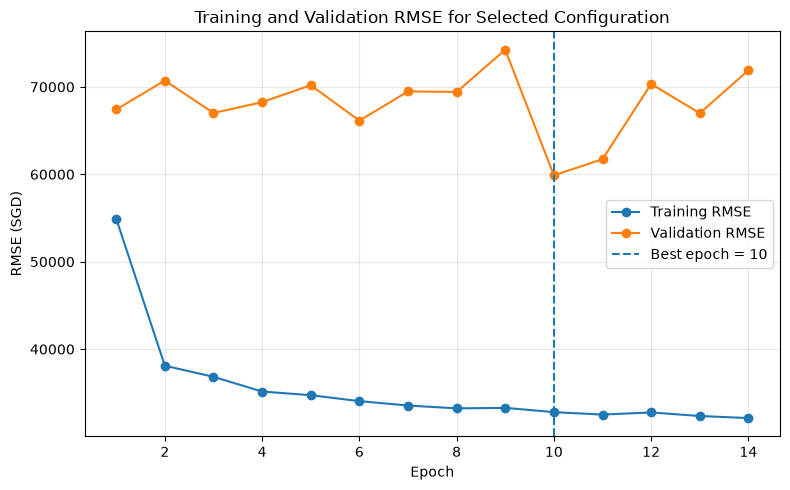

In [17]:
train_history = selected_result["train_rmse_history"]
validation_history = selected_result["validation_rmse_history"]
epochs = range(1, len(train_history) + 1)

plt.figure(figsize=(8, 5))

plt.plot(epochs, train_history, marker="o", label="Training RMSE")
plt.plot(epochs, validation_history, marker="o", label="Validation RMSE")
plt.axvline(
    selected_result["best_epoch"],
    linestyle="--",
    label=f'Best epoch = {selected_result["best_epoch"]}'
)

plt.xlabel("Epoch")
plt.ylabel("RMSE (SGD)")
plt.title("Training and Validation RMSE for Selected Configuration")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "selected_train_validation_rmse.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 6. Retraining on combined train and validation data

After model selection, 2017–2021 are treated as the final training data. Categorical encoders, continuous-feature scaling statistics, and target scaling statistics are re-fit on this combined data. The 2022 test set is transformed using these fitted quantities and is not used to select hyperparameters or the number of epochs.

### 6.1 Combined-data preprocessing

In [29]:
def prepare_combined_data(csv_path, config):
    df = pd.read_csv(csv_path)
    rows = df.to_dict(orient="records")

    combined_rows = [
        row for row in rows
        if int(row["year"]) in config.train_years
        or int(row["year"]) == config.validation_year
    ]

    test_rows = [
        row for row in rows
        if int(row["year"]) == config.test_year
    ]

    # Fit categorical encoders on combined train + validation data
    category_maps = {}

    for name in config.categorical_features:
        values = sorted({row[name] for row in combined_rows})
        category_maps[name] = {
            value: index + 1
            for index, value in enumerate(values)
        }

    # Fit continuous-feature scaling on combined train + validation data
    combined_continuous = torch.tensor(
        [
            [float(row[name]) for name in config.continuous_features]
            for row in combined_rows
        ],
        dtype=torch.float32
    )

    means = combined_continuous.mean(dim=0)
    stds = combined_continuous.std(dim=0).clamp_min(1e-8)

    # Fit target scaling on combined train + validation data
    combined_target = torch.tensor(
        [float(row["resale_price"]) for row in combined_rows],
        dtype=torch.float32
    )

    target_mean = combined_target.mean().item()
    target_std = combined_target.std(correction=0).clamp_min(1e-8).item()

    return {
        "combined": make_dataset(
            combined_rows,
            category_maps,
            means,
            stds,
            config
        ),
        "test": make_dataset(
            test_rows,
            category_maps,
            means,
            stds,
            config
        ),
        "cardinalities": [
            len(category_maps[name]) + 1
            for name in config.categorical_features
        ],
        "continuous_mean": means,
        "continuous_std": stds,
        "target_mean": target_mean,
        "target_std": target_std
    }

### 6.2 Train the selected baseline

The final model is trained for the **10 epochs selected in A1**. The test RMSE curve is recorded only for the assignment plot; it is not used to choose an epoch. Therefore the saved model is the epoch-10 model even if an earlier test RMSE happens to be lower.

In [30]:
def train_baseline(seed, verbose=True):
    config = Config(
        seed=seed,
        hidden_width=HIDDEN_WIDTH,
        embedding_dims=(EMBEDDING_DIM,) * 4
    )

    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)

    data = prepare_combined_data(DATA_PATH, config)

    combined_data = data["combined"]

    model = PriceModel(
        data["cardinalities"],
        data["target_mean"],
        data["target_std"],
        config
    )

    train_loader = DataLoader(
        combined_data,
        batch_size=config.batch_size,
        shuffle=True
    )

    loss_function = nn.MSELoss()
    optimiser = torch.optim.Adam(model.parameters(), lr=config.learning_rate)

    train_rmse_history = []
    test_rmse_history = []

    for epoch in range(1, NUM_EPOCHS + 1):
        model.train()

        squared_error = 0.0
        row_count = 0

        for categorical, continuous, target in train_loader:
            optimiser.zero_grad()

            standard_prediction = model(categorical, continuous)
            standard_target = (target - model.target_mean) / model.target_std

            loss = loss_function(standard_prediction, standard_target)
            loss.backward()
            optimiser.step()

            prediction = standard_prediction.detach() * model.target_std + model.target_mean

            squared_error += (prediction - target).square().sum().item()
            row_count += len(target)

        train_rmse = (squared_error / row_count) ** 0.5
        test_rmse = calculate_rmse(model, data["test"], config.batch_size)

        train_rmse_history.append(train_rmse)
        test_rmse_history.append(test_rmse)

        if verbose:
            print(
                f"epoch {epoch:02d} | "
                f"train RMSE {train_rmse:,.2f} | "
                f"test RMSE {test_rmse:,.2f}"
            )

    test_rmse, test_r2 = evaluate_regression(
        model,
        data["test"],
        config.batch_size
    )

    return {
        "seed": seed,
        "model": model,
        "config": config,
        "data": data,
        "train_rmse_history": train_rmse_history,
        "test_rmse_history": test_rmse_history,
        "test_rmse": test_rmse,
        "test_r2": test_r2
    }

In [31]:
baseline_result = train_baseline(seed=42, verbose=True)

epoch 01 | train RMSE 57,874.18 | test RMSE 108,292.68
epoch 02 | train RMSE 45,431.96 | test RMSE 103,193.74
epoch 03 | train RMSE 43,575.22 | test RMSE 100,445.73
epoch 04 | train RMSE 42,515.07 | test RMSE 99,718.50
epoch 05 | train RMSE 41,876.66 | test RMSE 109,876.23
epoch 06 | train RMSE 41,496.39 | test RMSE 93,831.25
epoch 07 | train RMSE 40,973.64 | test RMSE 104,774.46
epoch 08 | train RMSE 40,524.42 | test RMSE 107,624.12
epoch 09 | train RMSE 40,320.54 | test RMSE 104,321.05
epoch 10 | train RMSE 40,020.12 | test RMSE 100,144.01


### 6.3 Training and test RMSE curves

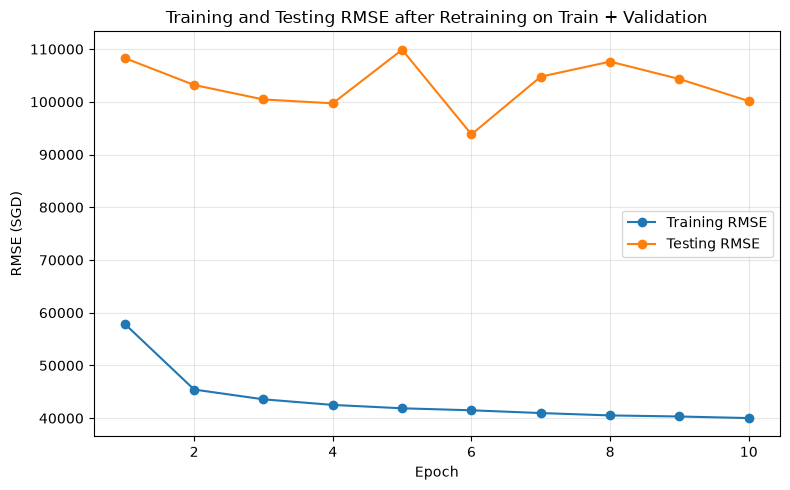

In [32]:
epochs = range(1, NUM_EPOCHS + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    baseline_result["train_rmse_history"],
    marker="o",
    label="Training RMSE"
)

plt.plot(
    epochs,
    baseline_result["test_rmse_history"],
    marker="o",
    label="Testing RMSE"
)

plt.xlabel("Epoch")
plt.ylabel("RMSE (SGD)")
plt.title("Training and Testing RMSE after Retraining on Train + Validation")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "final_train_test_rmse.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 6.4 Final test performance

In [33]:
print(f"Final Test RMSE: SGD {baseline_result['test_rmse']:,.2f}")
print(f"Final Test R²: {baseline_result['test_r2']:.4f}")

Final Test RMSE: SGD 100,144.01
Final Test R²: 0.6540


In [34]:
torch.save(
    baseline_result["model"].state_dict(),
    OUTPUT_DIR / "selected_baseline_model.pt"
)

## 7. A1 results and interpretation

**Baseline architecture.** The supplied baseline contains **3,505 trainable parameters**.

**Hyperparameter selection.** The grid search selected:
- hidden-layer width = **256**
- shared embedding dimension = **2**
- best epoch = **10**
- best validation RMSE = **SGD 59,880.89**

The training/validation curves show a substantial generalisation gap. Training RMSE decreases steadily, while validation RMSE is much higher and fluctuates strongly. Validation performance is best at epoch 10; afterwards training error remains low while validation RMSE worsens. This is evidence of **overfitting rather than underfitting**. The width of 256 provides relatively high capacity and may contribute to this behaviour, but the grid-search evidence does not justify claiming that the width is simply “too large”, because this configuration achieved the best validation RMSE among the candidates.

**Final retraining.** After preprocessing is re-fit on the combined 2017–2021 data, the selected architecture is retrained for 10 epochs. The final epoch-10 model obtains:
- test RMSE = **SGD 100,144.01**
- test $R^2$ = **0.6540**

Although the plotted test RMSE is lower at an earlier epoch, the epoch is **not** re-selected using the test set. The number of epochs remains 10 because it was chosen using validation data before final retraining.